# Project Name : Credit Card Fraud Detection using PyCaret

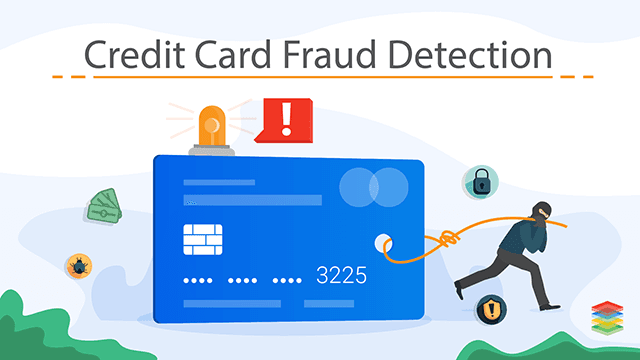

#### In this project we will be first making our redictions using Machine Learning Techniques then we will be using Auto ML Technique to do the same. We will be using PyCaret in this notebook 

## Context 
### It is important that credit card companies are able to recognize fraudulent credit card transactions so that customers are not charged for items that they did not purchase

### In this project we will be implementing Anamoly detection to detect wheteher there is any fraudulent transaction.

## Content
### The dataset contains transactions made by credit cards in September 2013 by European cardholders.
### This dataset presents transactions that occurred in two days, where we have 492 frauds out of 284,807 transactions. The dataset is highly unbalanced, the positive class (frauds) account for 0.172% of all transactions.

### It contains only numerical input variables which are the result of a PCA transformation. Unfortunately, due to confidentiality issues, we cannot provide the original features and more background information about the data. Features V1, V2, … V28 are the principal components obtained with PCA, the only features which have not been transformed with PCA are 'Time' and 'Amount'. Feature 'Time' contains the seconds elapsed between each transaction and the first transaction in the dataset. The feature 'Amount' is the transaction Amount, this feature can be used for example-dependant cost-sensitive learning. Feature 'Class' is the response variable and it takes value 1 in case of fraud and 0 otherwise.

### Given the class imbalance ratio, we recommend measuring the accuracy using the Area Under the Precision-Recall Curve (AUPRC). Confusion matrix accuracy is not meaningful for unbalanced classification.

## In this notebook we will perform the following task: 
- Data Analysis
- Feature Engineering
- Model Building and Prediction using ML Techniques
- Model Building and Prediction using PyCaret(Auto ML)

### Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import scipy
from sklearn.metrics import classification_report,accuracy_score

### Importing Libraries for Outlier Detection

In [2]:
from sklearn.ensemble import IsolationForest

from sklearn.svm import OneClassSVM

Task was destroyed but it is pending!
task: <Task pending name='Task-32' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at C:\Users\ASUS TUF\anaconda3\envs\ml\lib\site-packages\ipykernel\utils.py:76> wait_for=<Task pending name='Task-33' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\ASUS TUF\anaconda3\envs\ml\lib\site-packages\ipykernel\utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\ASUS TUF\anaconda3\envs\ml\lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\ASUS TUF\anaconda3\envs\ml\lib\site-packages\sklearn\tree\_classes.py:44: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  from . import _criterion, _splitter, _tree
Task was destroyed but it is pending!
task: <Task pending name='Task-33' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\ASUS TUF\anaconda3\envs\ml\lib\site-packages\ipykernel\utils.py:68> cb

### Reading our Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [3]:
df= pd.read_csv("creditcard.csv")

In [ ]:
df.head()

### Data Analysis

In [ ]:
df.shape

#### Checking Null Values

In [ ]:
df.isnull().sum()

### Checking the distribution of Normal and Fraud cases in our Data Set

In [ ]:
import plotly.express as px
import plotly.graph_objects as go

In [ ]:
fraud_check = pd.value_counts(df['Class'], sort = True)
fraud_check.plot(kind = 'bar', rot=0, color= 'r')
plt.title("Normal and Fraud Distribution")
plt.xlabel("Class")
plt.ylabel("Frequency")
labels= ['Normal','Fraud']
plt.xticks(range(2), labels)
plt.show()

## Using Plotly to visualize the class imbalance

In [ ]:
fraud_check = df['Class'].value_counts().reset_index()
fraud_check.columns = ['Class', 'Frequency']
fraud_check['Class'] = ['Normal', 'Fraud']
fig = px.bar(fraud_check, x='Class', y='Frequency', color='Class')
fig.update_yaxes(type='log')
fig.show()


#### Let us see what is the shape of Normal and Fraud data set

In [ ]:
fraud_people = df[df['Class']==1]
normal_people = df[df['Class']==0]

In [ ]:
fraud_people.shape

In [ ]:
normal_people.shape

#### Finding out the avg amount in our both the data sets

In [ ]:
fraud_people['Amount'].describe()

In [ ]:
normal_people['Amount'].describe()

#### Let us analyse it visually

In [ ]:
graph, (plot1, plot2) = plt.subplots(2,1,sharex= True)
graph.suptitle('Average amount per class')
bins = 70

plot1.hist(fraud_people['Amount'] , bins = bins)
plot1.set_title('Fraud Amount')

plot2.hist(normal_people['Amount'] , bins = bins)
plot2.set_title('Normal Amount')

plt.xlabel('Amount ($)')
plt.ylabel('Number of Transactions')
plt.yscale('log')
plt.show();

In [ ]:
from plotly.subplots import make_subplots

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    subplot_titles=("Fraud Amount", "Normal Amount")
)

fig.add_trace(
    go.Histogram(x=fraud_people['Amount'], nbinsx=70, name='Fraud'),
    row=1, col=1
)

fig.add_trace(
    go.Histogram(x=normal_people['Amount'], nbinsx=70, name='Normal'),
    row=2, col=1
)

fig.update_layout(
    title='Average Amount per Class',
    xaxis2_title='Amount ($)',
    yaxis_title='Number of Transactions',
    yaxis2_title='Number of Transactions',
    height=700,
    showlegend=False
)

fig.update_yaxes(type='log')

fig.show()

#### Plotting a corr Heatmap

In [ ]:
df.corr()
plt.figure(figsize=(30,30))
g=sns.heatmap(df.corr(),annot=True)

### Creating our Dependent and Independent Features

In [ ]:
# columns = df.columns.tolist()
# # Making our Independent Features
# columns = [var for var in columns if var not in ["Class"]]
# # Making our Dependent Variable
# target = "Class"
x= df.drop("Class",axis=1)
y= df["Class"]

In [ ]:
x.shape

In [ ]:
y.shape

In [ ]:
x.head() ## Independent Variable

In [ ]:
y.head() ## Dependent Variable

## Model building

### Splitting the data

In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30,stratify=y, random_state=42)

### We wil be using the following Models for our Anamoly Detection:
- Isolation Forest
- OneClassSVM

## Isolation Forest

#### One of the newest techniques to detect anomalies is called Isolation Forests. The algorithm is based on the fact that anomalies are data points that are few and different. As a result of these properties, anomalies are susceptible to a mechanism called isolation.

#### This method is highly useful and is fundamentally different from all existing methods. It introduces the use of isolation as a more effective and efficient means to detect anomalies than the commonly used basic distance and density measures. Moreover, this method is an algorithm with a low linear time complexity and a small memory requirement. It builds a good performing model with a small number of trees using small sub-samples of fixed size, regardless of the size of a data set.

#### Typical machine learning methods tend to work better when the patterns they try to learn are balanced, meaning the same amount of good and bad behaviors are present in the dataset.

#### How Isolation Forests Work The Isolation Forest algorithm isolates observations by randomly selecting a feature and then randomly selecting a split value between the maximum and minimum values of the selected feature. The logic argument goes: isolating anomaly observations is easier because only a few conditions are needed to separate those cases from the normal observations. On the other hand, isolating normal observations require more conditions. Therefore, an anomaly score can be calculated as the number of conditions required to separate a given observation.

#### The way that the algorithm constructs the separation is by first creating isolation trees, or random decision trees. Then, the score is calculated as the path length to isolate the observation

In [ ]:
iso_forest= IsolationForest(n_estimators=100, max_samples=len(x_train),random_state=0, verbose=0)                        

In [ ]:
best_isof=grid.best_estimator_

In [ ]:
iso_forest.fit(x_train,y_train)

In [ ]:
ypred= iso_forest.predict(x_test)

In [ ]:
ypred

#### Mapping the values as we want to have an output in 0 and 1

In [ ]:
ypred[ypred == 1] = 0 # ligitimate transaction
ypred[ypred == -1] = 1 # Fraudulant transaction 


### Accuracy score and Matrix

In [ ]:
print(accuracy_score(y_test,ypred))

In [ ]:
print(classification_report(y_test,ypred))

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
confusion_matrix(y_test, ypred)

### We can also print how many errors our model have

In [ ]:
n_errors = (ypred != y_test).sum()
print("Isolation Forest have {} errors.".format(n_errors))

## OneClassSVM

In [ ]:
svm= OneClassSVM(kernel='rbf', degree=3, gamma=0.1,nu=0.05, 
                                        max_iter=-1)

In [ ]:
svm.fit(x_train,y_train)

In [ ]:
ypred1= svm.predict(x_test)

#### Here also we do the same thing as above, mapping our results in 0 and 1

In [ ]:
ypred1[ypred1 == 1] = 0
ypred1[ypred1 == -1] = 1

### Accuracy score and Matrix

In [ ]:
print(accuracy_score(y_test,ypred))

In [ ]:
print(classification_report(y_test,ypred))

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
confusion_matrix(y_test, ypred)

In [ ]:
n_errors = (ypred1 != y_test).sum()
print("SVM have {} errors.".format(n_errors))

## Solving the Problem Statement using PyCaret Library(Auto ML)

In [3]:
df= pd.read_csv("creditcard.csv")

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Model Developement 

In [5]:
from pycaret.classification import *

In [6]:
model= setup(data= df, target= 'Class')

,Description,Value
0,Session id,1834
1,Target,Class
2,Target type,Binary
3,Original data shape,"(284807, 31)"
4,Transformed data shape,"(284807, 31)"
5,Transformed train set shape,"(199364, 31)"
6,Transformed test set shape,"(85443, 31)"
7,Numeric features,30
8,Preprocess,True
9,Imputation type,simple


In [7]:
compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9996,0.9490,0.8106,0.9565,0.8752,0.8750,0.8792,20.0130
et,Extra Trees Classifier,0.9996,0.9533,0.8077,0.9592,0.8753,0.8751,0.8792,3.5730
catboost,CatBoost Classifier,0.9996,0.9835,0.8164,0.9629,0.8824,0.8822,0.8858,12.5120
lda,Linear Discriminant Analysis,0.9994,0.9839,0.7582,0.8640,0.8062,0.8059,0.8083,0.2030
lr,Logistic Regression,0.9993,0.9698,0.6823,0.8709,0.7621,0.7617,0.7689,5.7570
ada,Ada Boost Classifier,0.9993,0.9752,0.7324,0.8306,0.7758,0.7755,0.7783,7.4150
dt,Decision Tree Classifier,0.9992,0.8790,0.7584,0.7766,0.7649,0.7645,0.7658,2.0590
gbc,Gradient Boosting Classifier,0.9990,0.6616,0.5441,0.7995,0.6323,0.6318,0.6503,38.5950
ridge,Ridge Classifier,0.9989,0.9839,0.4500,0.8458,0.5833,0.5828,0.6141,0.1280
knn,K Neighbors Classifier,0.9984,0.6118,0.0754,0.8800,0.1360,0.1358,0.2475,5.0820


RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=1834, verbose=0,
                       warm_start=False)

In [9]:
best = compare_models(sort="MCC")

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
catboost,CatBoost Classifier,0.9996,0.9835,0.8164,0.9629,0.8824,0.8822,0.8858,11.8360
rf,Random Forest Classifier,0.9996,0.9490,0.8106,0.9565,0.8752,0.8750,0.8792,19.6900
et,Extra Trees Classifier,0.9996,0.9533,0.8077,0.9592,0.8753,0.8751,0.8792,3.2720
lda,Linear Discriminant Analysis,0.9994,0.9839,0.7582,0.8640,0.8062,0.8059,0.8083,0.1980
ada,Ada Boost Classifier,0.9993,0.9752,0.7324,0.8306,0.7758,0.7755,0.7783,6.9520
lr,Logistic Regression,0.9993,0.9698,0.6823,0.8709,0.7621,0.7617,0.7689,5.6640
dt,Decision Tree Classifier,0.9992,0.8790,0.7584,0.7766,0.7649,0.7645,0.7658,1.9780
xgboost,Extreme Gradient Boosting,0.9947,0.8859,0.7045,0.7767,0.7365,0.7359,0.7374,0.5660
gbc,Gradient Boosting Classifier,0.9990,0.6616,0.5441,0.7995,0.6323,0.6318,0.6503,36.6810
ridge,Ridge Classifier,0.9989,0.9839,0.4500,0.8458,0.5833,0.5828,0.6141,0.1210


As we see **CatBoost** is the winner across all the optimization metric 

### Searching for the best hyperparameter configuration

In [10]:
tuned_model= tune_model(best,optimize="MCC")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9994,0.9795,0.7143,0.9615,0.8197,0.8194,0.8285
1,0.9997,0.9527,0.8857,0.9394,0.9118,0.9116,0.9120
2,0.9997,0.9960,0.8571,1.0000,0.9231,0.9230,0.9257
3,0.9998,0.9929,0.8857,1.0000,0.9394,0.9393,0.9410
4,0.9995,0.9600,0.7353,1.0000,0.8475,0.8472,0.8573
5,0.9994,0.9814,0.7059,0.9600,0.8136,0.8133,0.8229
6,0.9995,0.9933,0.8235,0.8750,0.8485,0.8482,0.8486
7,0.9997,0.9779,0.8529,1.0000,0.9206,0.9205,0.9234
8,0.9994,0.9808,0.7941,0.8710,0.8308,0.8305,0.8314


Fitting 10 folds for each of 10 candidates, totalling 100 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


### Searching for threshold that maximizes the MCC 
MCC has been chosen to find a balance  between __Precision__ (optimize for customer experience) and __Recall__ (minimum Fraud transaction)

## Threshold optimizer 

In [22]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    accuracy_score,
)
def optimize_threshold(
    model,
    X_test,
    y_test,
    metric="mcc",
    step=0.01,
):
    """
    Optimize the classification threshold for any sklearn-compatible classifier.

    Parameters
    ----------
    model : trained classifier
        Must implement predict_proba().

    X_test : array-like
        Test features.

    y_test : array-like
        True labels.

    metric : str
        One of:
        'mcc'
        'precision'
        'recall'
        'f1'
        'accuracy'

    step : float
        Threshold increment.
    """

    probabilities = model.predict_proba(X_test)[:, 1]

    thresholds = np.arange(step, 1, step)

    results = []

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        precision = precision_score(
            y_test,
            predictions,
            zero_division=0,
        )

        recall = recall_score(
            y_test,
            predictions,
            zero_division=0,
        )

        f1 = f1_score(
            y_test,
            predictions,
            zero_division=0,
        )

        mcc = matthews_corrcoef(
            y_test,
            predictions,
        )

        accuracy = accuracy_score(
            y_test,
            predictions,
        )

        results.append(
            {
                "Threshold": threshold,
                "Precision": precision,
                "Recall": recall,
                "F1": f1,
                "MCC": mcc,
                "Accuracy": accuracy,
            }
        )

    results = pd.DataFrame(results)

    metric = metric.upper()

    best = results.loc[
        results[metric].idxmax()
    ]

    return results, best

In [20]:
from pycaret.classification import get_config

X_test = get_config("X_test")
y_test = get_config("y_test")

In [23]:
results, best = optimize_threshold(
    tuned_model,
    X_test,
    y_test,
    metric="mcc",
)

In [26]:
results.sort_values(by='MCC',ascending=False).head(10)

,Threshold,Precision,Recall,F1,MCC,Accuracy
19,0.20,0.932773,0.750000,0.831461,0.836162,0.999473
25,0.26,0.940171,0.743243,0.830189,0.835684,0.999473
24,0.25,0.940171,0.743243,0.830189,0.835684,0.999473
35,0.36,0.947826,0.736486,0.828897,0.835259,0.999473
36,0.37,0.947826,0.736486,0.828897,0.835259,0.999473
37,0.38,0.947826,0.736486,0.828897,0.835259,0.999473
38,0.39,0.947826,0.736486,0.828897,0.835259,0.999473
39,0.40,0.947826,0.736486,0.828897,0.835259,0.999473
40,0.41,0.947826,0.736486,0.828897,0.835259,0.999473
41,0.42,0.947826,0.736486,0.828897,0.835259,0.999473


Thresholds ranging from 0.01 to 0.99 were evaluated using __Matthews Correlation Coefficient__ as the optimization criterion. No threshold outperformed the default decision threshold `(0.50)`. Therefore, the default operating threshold was retained."

## Model Eavaluation 

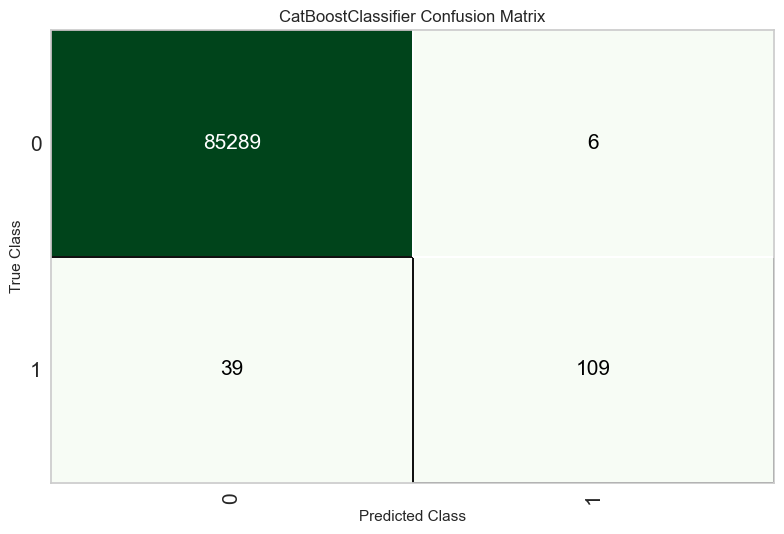

In [30]:
plot_model(tuned_model, plot="confusion_matrix")

### Explaination
The confusion matrix demonstrates that the CatBoost classifier performs exceptionally well on legitimate transactions, correctly classifying __85,289__ out of __85,295__ while generating only __6 false positives__. For the fraud class, the model correctly identified __109__ fraudulent transactions but failed to detect __39__, resulting in __false negatives__.  This behavior reflects a model with very high precision, minimizing unnecessary customer disruptions, while maintaining a strong recall for fraud detection. 

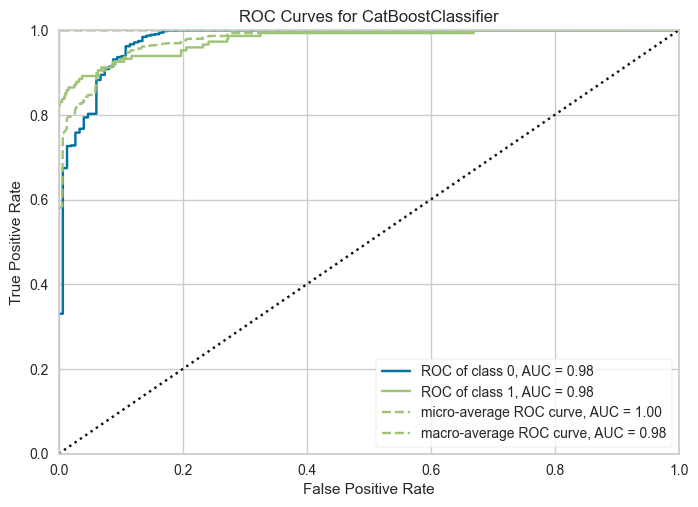

In [31]:
plot_model(tuned_model, plot="auc")

### ROC_Interpretation

The ROC curve demonstrates the trade-off between the __True Positive Rate (Recall)__ and the __False Positive Rate__ across different classification thresholds. The model's AUC of `0.98` indicates excellent discriminative ability, meaning it can effectively distinguish fraudulent transactions from legitimate ones. This suggests that the CatBoost classifier achieves high fraud detection performance while maintaining a relatively low false positive rate over a wide range of thresholds.

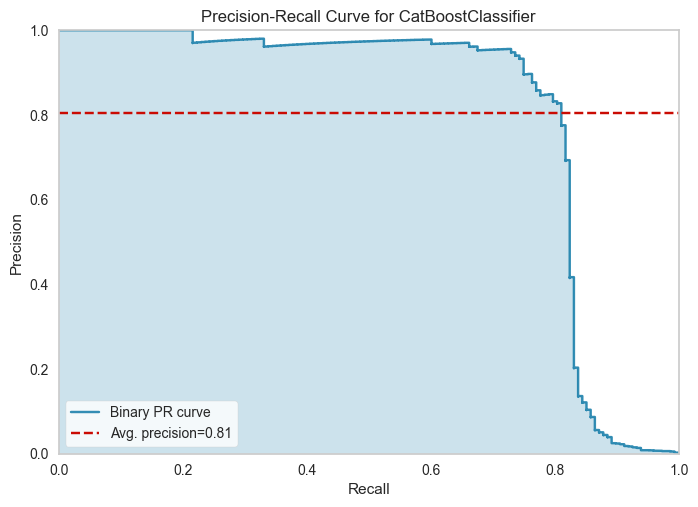

In [32]:
plot_model(tuned_model, plot="pr")

### Precison-Recall interpretation

Precision remains very high until the recall reaches approximately `0.80`. Beyond this point, precision declines sharply, indicating that the model has already identified most of the easily distinguishable fraudulent transactions. Achieving higher recall requires lowering the decision threshold, which results in a substantial increase in false positives.

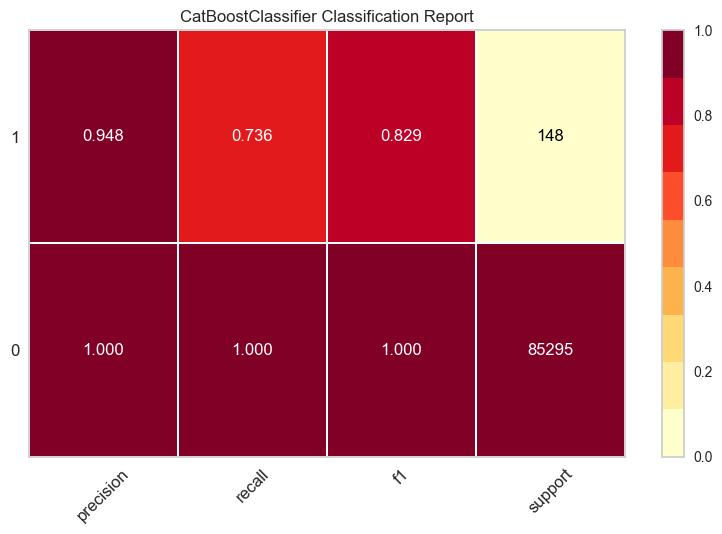

In [43]:
plot_model(tuned_model, plot="class_report")

### Classification report Interpretation 

The classification report shows that the CatBoost classifier performs exceptionally well on legitimate transactions, achieving perfect precision, recall, and F1-score due to the overwhelming majority of correctly classified legitimate transactions. For the fraud class, the model achieved a precision of `94.8%`, indicating that very few legitimate transactions were incorrectly flagged as fraud. Its recall of `73.6%` shows that approximately three-quarters of fraudulent transactions were successfully detected, while the remaining quarter were missed. The resulting F1-score of `82.9%` demonstrates a strong balance between fraud detection and minimizing false alarms.

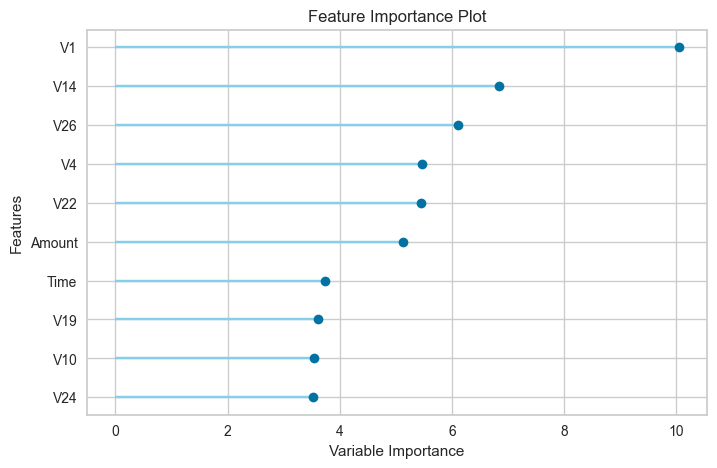

In [34]:
plot_model(tuned_model, plot="feature")

### Feature Importance

The feature importance analysis indicates that the CatBoost classifier ___relies primarily on___  a small subset of the available features. Among the 30 variables, V1 is the most influential predictor, followed by V14, V26, V4, V22, V10, V24, V19, Amount, and Time. These features ___contribute the most___ to the model's decision-making process, whereas the remaining variables have a ___comparatively smaller influence___ on the final predictions.

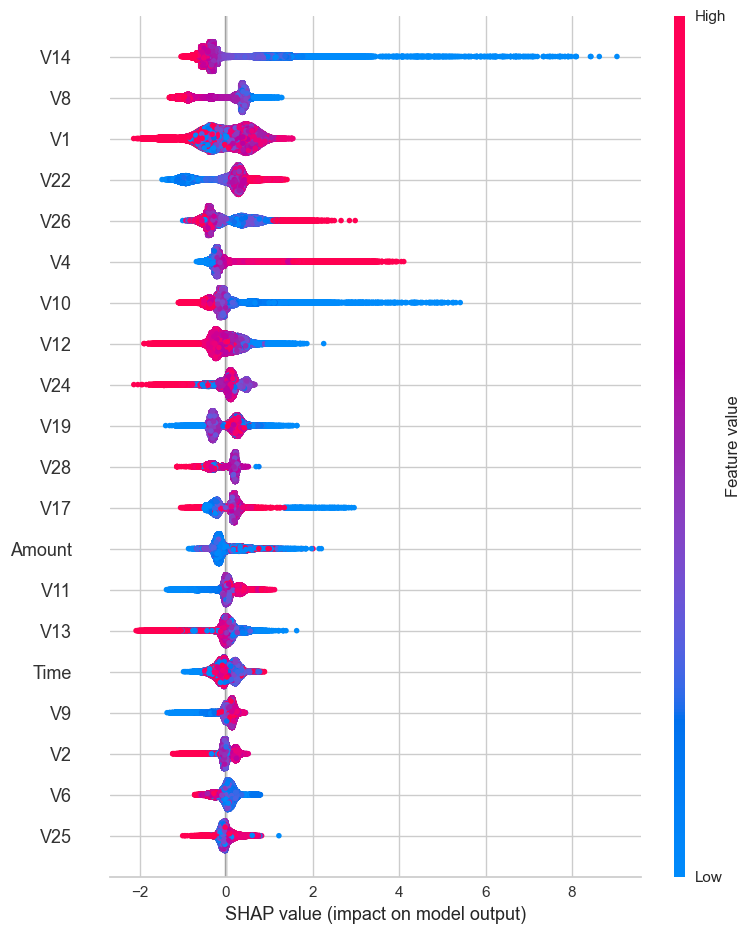

In [36]:
interpret_model(tuned_model, plot="summary")

### SHAP analysis 

Feature importance identifies __V1__ as the most frequently influential predictor during model training, whereas the SHAP analysis highlights __V14__ as having the greatest impact on the model's predictions. This difference arises because feature importance measures a feature's overall contribution to model construction, while SHAP quantifies its influence on individual predictions.

## Model finalisation 
Training the Catboost on the hold-out test set 

In [46]:
final_model = finalize_model(tuned_model)

In [47]:
save_model(final_model, "catboost_fraud_detector")

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('numerical_imputer',
                  TransformerWrapper(exclude=None,
                                     include=['Time', 'V1', 'V2', 'V3', 'V4',
                                              'V5', 'V6', 'V7', 'V8', 'V9',
                                              'V10', 'V11', 'V12', 'V13', 'V14',
                                              'V15', 'V16', 'V17', 'V18', 'V19',
                                              'V20', 'V21', 'V22', 'V23', 'V24',
                                              'V25', 'V26', 'V27', 'V28',
                                              'Amount'],
                                     transformer=SimpleImputer(add_indicator=False,
                                                               copy=True,
                                                               fill_value=...
                                                               strategy='mean'))),
                 ('cate

## Testing the  deployment pipeline

In [48]:
new_transactions = ( df.drop(columns="Class").sample(10, random_state=42))

In [49]:
predictions = predict_model(final_model, data=new_transactions)
print(predictions)

            Time         V1        V2         V3        V4         V5  \
43428    41505.0 -16.526506  8.584971 -18.649853  9.505593 -13.793818   
49906    44261.0   0.339812 -2.743745  -0.134070 -1.385729  -1.451413   
29474    35484.0   1.399590 -0.590701   0.168619 -1.029950  -0.539806   
276481  167123.0  -0.432071  1.647895  -1.669361 -0.349504   0.785785   
278846  168473.0   2.014160 -0.137394  -1.015839  0.327269  -0.182179   
101565   67878.0  -0.641330 -0.057304   1.489998 -1.688131  -1.151043   
260880  159763.0   2.023952 -0.120140  -1.086918  0.423019  -0.142901   
214337  139631.0  -0.688944  1.292153  -0.564281 -1.457526   2.258333   
201575  133944.0   2.119363  0.142639  -2.373337  0.541949   0.608419   
81055    58769.0  -5.584256 -4.732413  -0.448452 -0.121442  -0.707412   

              V6         V7        V8        V9  ...       V22       V23  \
43428  -2.832404 -16.701694  7.517344 -8.507059  ... -1.127670 -2.358579   
49906   1.015887  -0.524379  0.224060  0.899

The code below verify wheather the prediction_label aligns with the target class

In [50]:
sample = df.loc[new_transactions.index, ["Class"]]

comparison = sample.join(
    predictions[["prediction_label", "prediction_score"]]
)

comparison

,Class,prediction_label,prediction_score
43428,1,1,1.0
49906,0,0,1.0
29474,0,0,1.0
276481,0,0,1.0
278846,0,0,1.0
101565,0,0,1.0
260880,0,0,1.0
214337,0,0,1.0
201575,0,0,1.0
81055,0,0,1.0


In [51]:
proba = final_model.predict_proba(new_transactions)

print(proba)

[[1.91418336e-05 9.99980858e-01]
 [9.99999312e-01 6.88344279e-07]
 [9.99984432e-01 1.55681591e-05]
 [9.99988838e-01 1.11615136e-05]
 [9.99999296e-01 7.04135294e-07]
 [9.99988033e-01 1.19669645e-05]
 [9.99999880e-01 1.20182513e-07]
 [9.99991865e-01 8.13494598e-06]
 [9.99999155e-01 8.45278892e-07]
 [9.99999795e-01 2.04658556e-07]]
